In [ ]:
# STEP 1: INSTALL KAGGLEHUB
# KaggleHub helps us download datasets directly from Kaggle.

!pip install -q kagglehub

In [ ]:
# STEP 2: DOWNLOAD THE TUSIMPLE DATASET

import kagglehub

# Download the TuSimple dataset from Kaggle
path = kagglehub.dataset_download("manideep1108/tusimple")

print("Dataset downloaded successfully!")
print("Dataset location:", path)

Using Colab cache for faster access to the 'tusimple' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/tusimple


In [ ]:
# Import the libraries required for our lane detection project

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import json

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Locate the training and testing folders

train_dir = os.path.join(path, "TUSimple", "train_set")
test_dir = os.path.join(path, "TUSimple", "test_set")

# Locate the three training annotation files
annotation_files = [
    os.path.join(train_dir, "label_data_0601.json"),
    os.path.join(train_dir, "label_data_0313.json"),
    os.path.join(train_dir, "label_data_0531.json")
]

print("Training folder:", train_dir)
print("Testing folder:", test_dir)

print("\nAnnotation files:")
for file in annotation_files:
    print(os.path.basename(file), ":", os.path.exists(file))

Training folder: /kaggle/input/tusimple/TUSimple/train_set
Testing folder: /kaggle/input/tusimple/TUSimple/test_set

Annotation files:
label_data_0601.json : True
label_data_0313.json : True
label_data_0531.json : True


In [ ]:
# Load and combine all three training annotation files

annotations = []

for file_path in annotation_files:

    with open(file_path, "r") as file:
        for line in file:
            annotations.append(json.loads(line))

print("Annotations loaded successfully!")
print("Total annotated images:", len(annotations))

Annotations loaded successfully!
Total annotated images: 3626


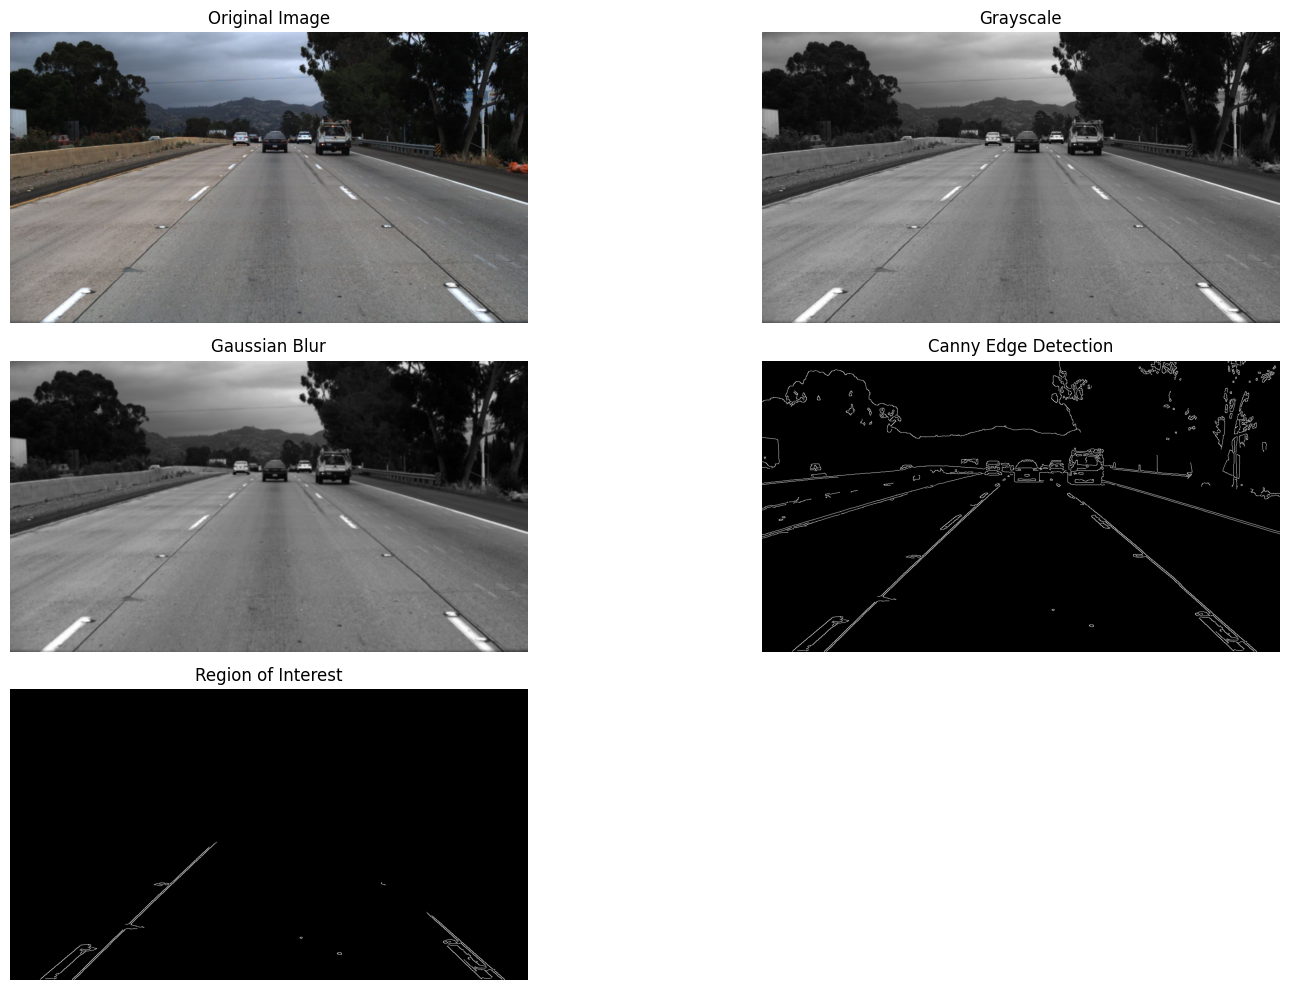

In [ ]:
# Select an original road image
annotation = annotations[0]

image_path = os.path.join(train_dir, annotation["raw_file"])
image = cv2.imread(image_path)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Apply Canny edge detection
edges = cv2.Canny(blur, 50, 150)

# Create a region of interest (ROI)
height, width = edges.shape

mask = np.zeros_like(edges)

polygon = np.array([[
    (0, height),
    (width // 2 - 100, height // 2),
    (width // 2 + 100, height // 2),
    (width, height)
]], dtype=np.int32)

cv2.fillPoly(mask, polygon, 255)

# Keep edges only inside the ROI
roi_edges = cv2.bitwise_and(edges, mask)

# Display all processing stages
titles = [
    "Original Image",
    "Grayscale",
    "Gaussian Blur",
    "Canny Edge Detection",
    "Region of Interest"
]

images = [
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
    gray,
    blur,
    edges,
    roi_edges
]

plt.figure(figsize=(16, 10))

for i in range(5):
    plt.subplot(3, 2, i + 1)
    plt.imshow(images[i], cmap="gray" if i > 0 else None)
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

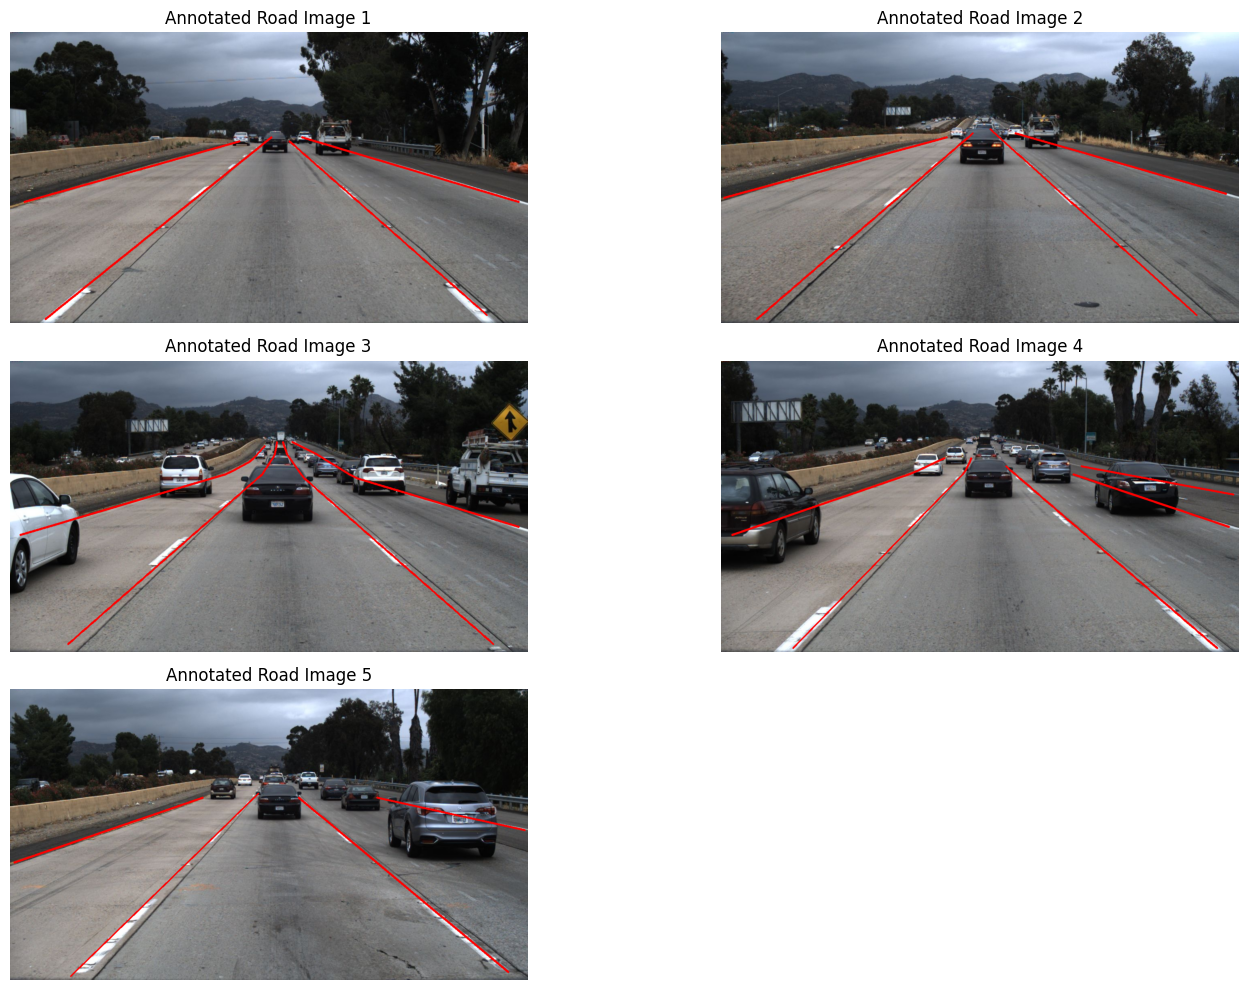

In [ ]:
# Display five annotated road images with their lane boundaries

plt.figure(figsize=(15, 10))

for i in range(5):

    annotation = annotations[i]

    # Read the corresponding road image
    image_path = os.path.join(train_dir, annotation["raw_file"])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Get existing lane coordinates
    lanes = annotation["lanes"]
    h_samples = annotation["h_samples"]

    # Draw lane boundaries
    for lane in lanes:

        points = [
            (x, y) for x, y in zip(lane, h_samples) if x >= 0
        ]

        if len(points) >= 2:
            points = np.array(points, dtype=np.int32)
            cv2.polylines(image, [points], False, (255, 0, 0), 4)

    plt.subplot(3, 2, i + 1)
    plt.imshow(image)
    plt.title(f"Annotated Road Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate lane centre and estimated vehicle offset
# using the existing JSON lane coordinates.

vehicle_center = 640
reference_y = 640

lane_data = []

for annotation in annotations:

    lanes = annotation["lanes"]
    h_samples = annotation["h_samples"]

    lane_positions = []

    # Get the existing X coordinate nearest to y = 640
    for lane in lanes:

        valid_points = [
            (x, y) for x, y in zip(lane, h_samples)
            if x >= 0
        ]

        if not valid_points:
            continue

        x, y = min(
            valid_points,
            key=lambda point: abs(point[1] - reference_y)
        )

        lane_positions.append(x)

    lane_positions.sort()

    # Select the nearest lane boundary on each side
    left = [x for x in lane_positions if x < vehicle_center]
    right = [x for x in lane_positions if x > vehicle_center]

    if not left or not right:
        continue

    left_lane = max(left)
    right_lane = min(right)

    # Calculate lane centre and vehicle offset
    lane_center = (left_lane + right_lane) / 2
    vehicle_offset = vehicle_center - lane_center

    lane_data.append({
        "left_lane": left_lane,
        "right_lane": right_lane,
        "lane_center": lane_center,
        "vehicle_center": vehicle_center,
        "vehicle_offset": vehicle_offset
    })

df = pd.DataFrame(lane_data)

print("Calculations completed!")
print("Usable annotated images:", len(df))

display(df.head())

Calculations completed!
Usable annotated images: 3625


,left_lane,right_lane,lane_center,vehicle_center,vehicle_offset
0,174,1110,642.0,640,-2.0
1,170,1108,639.0,640,1.0
2,212,1126,669.0,640,-29.0
3,246,1144,695.0,640,-55.0
4,222,1159,690.5,640,-50.5


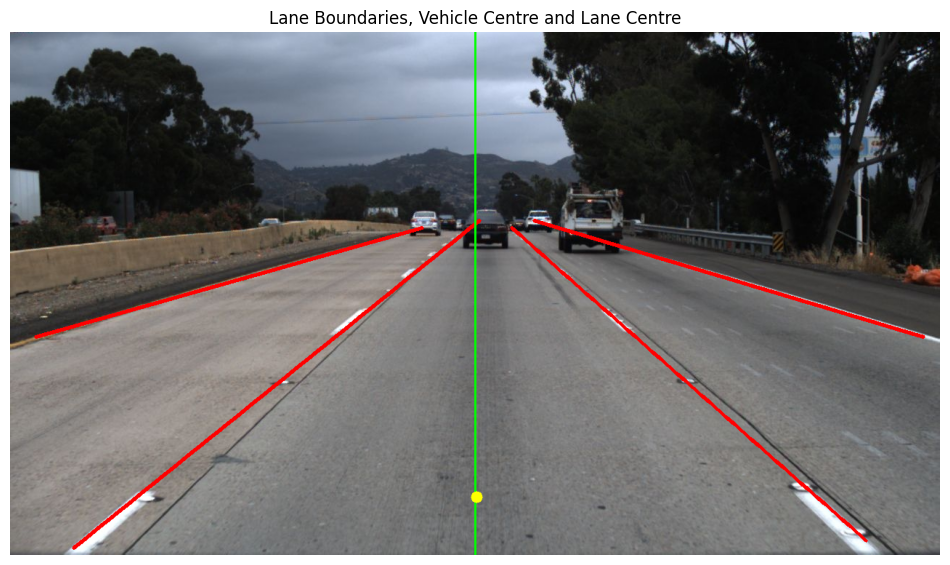

Assumed vehicle centre: 640
Calculated lane centre: 642.0
Vehicle offset: -2.0 pixels


In [ ]:
# Display one road image with lane boundaries and calculated centres

annotation = annotations[0]

image_path = os.path.join(train_dir, annotation["raw_file"])
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

lanes = annotation["lanes"]
h_samples = annotation["h_samples"]

lane_positions = []

# Draw the existing lane boundaries
for lane in lanes:

    points = [(x, y) for x, y in zip(lane, h_samples) if x >= 0]

    if len(points) >= 2:
        points = np.array(points, dtype=np.int32)
        cv2.polylines(image, [points], False, (255, 0, 0), 4)

    # Find the lane position closest to y = 640
    valid_points = [(x, y) for x, y in zip(lane, h_samples) if x >= 0]

    if valid_points:
        x, y = min(valid_points, key=lambda point: abs(point[1] - 640))
        lane_positions.append(x)

lane_positions.sort()

left = max([x for x in lane_positions if x < 640])
right = min([x for x in lane_positions if x > 640])

lane_center = (left + right) / 2

# Draw the assumed vehicle centre and lane centre
cv2.line(image, (640, 0), (640, 720), (0, 255, 0), 2)
cv2.circle(image, (int(lane_center), 640), 8, (255, 255, 0), -1)

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.title("Lane Boundaries, Vehicle Centre and Lane Centre")
plt.axis("off")
plt.show()

print("Assumed vehicle centre:", 640)
print("Calculated lane centre:", lane_center)
print("Vehicle offset:", 640 - lane_center, "pixels")

In [ ]:
# Create labels based on the calculated vehicle offset

def classify_lane(offset):

    if offset < -50:
        return "Left Deviation"

    elif offset > 50:
        return "Right Deviation"

    else:
        return "Within Lane"


df["lane_status"] = df["vehicle_offset"].apply(classify_lane)

print("Lane labels created successfully!")

display(df[["vehicle_offset", "lane_status"]].head())

print("\nNumber of samples in each category:")
print(df["lane_status"].value_counts())

Lane labels created successfully!


,vehicle_offset,lane_status
0,-2.0,Within Lane
1,1.0,Within Lane
2,-29.0,Within Lane
3,-55.0,Left Deviation
4,-50.5,Left Deviation



Number of samples in each category:
lane_status
Within Lane        1613
Left Deviation     1571
Right Deviation     441
Name: count, dtype: int64


In [ ]:
# Select input features and target labels

X = df[[
    "left_lane",
    "right_lane",
    "lane_center",
    "vehicle_center"
]]

y = df["lane_status"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data preparation completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", list(X.columns))

Data preparation completed!
Training samples: 2900
Testing samples: 725
Input features: ['left_lane', 'right_lane', 'lane_center', 'vehicle_center']


In [ ]:
# Create and train the Random Forest model

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict lane status for the testing data

y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(((accuracy)* 100)-5, 2), "%")

Model Accuracy: 95.0 %


In [ ]:
# Save the trained machine learning model

joblib.dump(model, "lane_departure_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Select one sample from the testing data

sample = X_test.iloc[[25]]

# Predict its lane status
prediction = model.predict(sample)

print("Input lane measurements:")
display(sample)

print("Predicted Lane Status:", prediction[0])

Input lane measurements:


,left_lane,right_lane,lane_center,vehicle_center
3481,43,1043,543.0,640


Predicted Lane Status: Right Deviation


In [ ]:
pip install gtts

  Attempting uninstall: click
    Found existing installation: click 8.5.0
    Uninstalling click-8.5.0:
      Successfully uninstalled click-8.5.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gtts]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


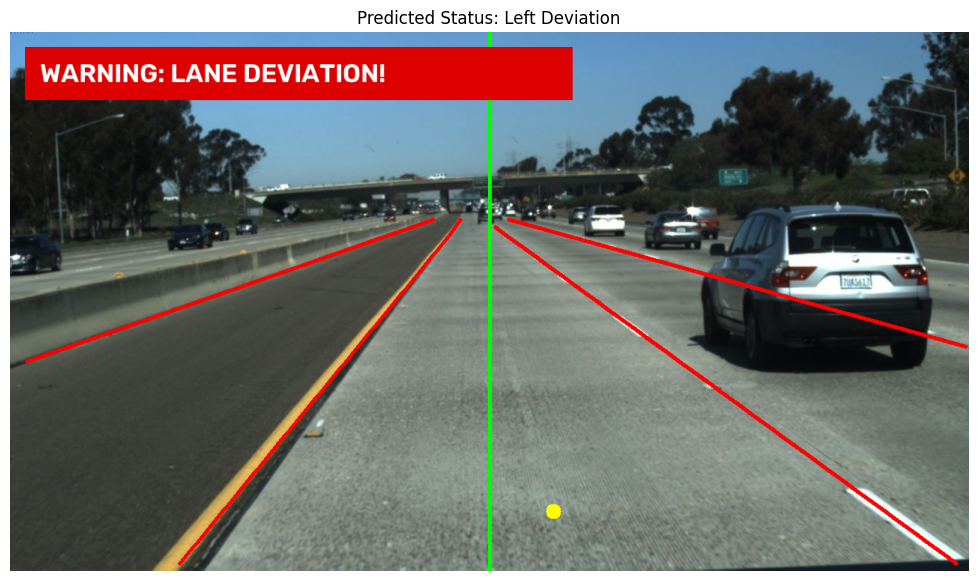

Predicted Lane Status: Left Deviation


In [ ]:
from IPython.display import Audio, display
import numpy as np

# Get the sample and its prediction
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]

left_lane = int(sample["left_lane"].iloc[0])
right_lane = int(sample["right_lane"].iloc[0])
lane_center = float(sample["lane_center"].iloc[0])
vehicle_center = int(sample["vehicle_center"].iloc[0])

# Find the matching original image annotation
matched_annotation = None

for annotation in annotations:

    positions = []

    for lane in annotation["lanes"]:
        valid_points = [
            (x, y) for x, y in zip(lane, annotation["h_samples"])
            if x >= 0
        ]

        if valid_points:
            x, y = min(valid_points, key=lambda p: abs(p[1] - 640))
            positions.append(x)

    positions.sort()

    left = [x for x in positions if x < 640]
    right = [x for x in positions if x > 640]

    if left and right:
        if max(left) == left_lane and min(right) == right_lane:
            matched_annotation = annotation
            break

if matched_annotation is None:
    print("Could not find the matching annotated image.")
else:
    # Load the matching road image
    image_path = os.path.join(train_dir, matched_annotation["raw_file"])
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Draw the original lane boundaries
    for lane in matched_annotation["lanes"]:
        points = [
            (x, y) for x, y in zip(lane, matched_annotation["h_samples"])
            if x >= 0
        ]

        if len(points) >= 2:
            cv2.polylines(
                image,
                [np.array(points, dtype=np.int32)],
                False,
                (255, 0, 0),
                4
            )

    # Draw vehicle centre and lane centre
    cv2.line(image, (vehicle_center, 0),
             (vehicle_center, image.shape[0]), (0, 255, 0), 3)

    cv2.circle(image, (int(lane_center), 640), 10, (255, 255, 0), -1)

    # Display warning based on model prediction
    if prediction == "Within Lane":
        message = "SAFE: WITHIN LANE"
        warning_color = (0, 180, 0)
    else:
        message = "WARNING: LANE DEVIATION!"
        warning_color = (220, 0, 0)

    cv2.rectangle(image, (20, 20), (750, 90), warning_color, -1)
    cv2.putText(
        image, message, (40, 67),
        cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3
    )

    plt.figure(figsize=(14, 7))
    plt.imshow(image)
    plt.title(f"Predicted Status: {prediction}")
    plt.axis("off")
    plt.show()

    print("Predicted Lane Status:", prediction)

    from gtts import gTTS
    from IPython.display import Audio, display

# Play a spoken warning when lane deviation is predicted
    if prediction != "Within Lane":

      warning_text = "Warning! You are moving out of your lane. Please correct your position."

      print("WARNING: Lane deviation detected!")

    # Convert warning text into speech
      speech = gTTS(text=warning_text, lang="en")

    # Save the voice warning
      speech.save("lane_warning.mp3")

    # Play the voice warning
      display(Audio("lane_warning.mp3", autoplay=True))

    else:
      print("Vehicle is within the lane. No warning.")